# Part I: First principles

In the first part of the lab, you will build and train two small machine-learning models using basic tensor operations. The purpose is to understand every step of the process: initializing weights, calculating an output and loss, deriving gradients, updating weights, and repeating this process during training.

Complete the TODOs in `first_principles_models.py` in the order in which they are introduced in this notebook. Work through each stage interactively, inspect the tensors, and verify that your implementations behave correctly. After changing the module, restart the notebook kernel and evaluate the notebook from the beginning so that the updated classes are imported.

For these exercises you should not use pre-implemented models or layers from `torch.nn` or their functional equivalents from `torch.nn.functional`. Also, you should not use `backward`, `autograd.grad`, and the `.grad` tensor attribute to calculate the gradients or an optimizer from `torch.optim` to update the weights. The purpose of these excercises is to implement these functionalities from scratch.

#### Setup

The following code imports all necessary dependencies, including the `first_principles_models.py` module.

In [1]:
import torch
import matplotlib.pyplot as plt

from first_principles_models import LinearModel, LinearSigmoidModel

from data import get_logo_as_rgb_image_tensor

from utilities import plot_grayscale_image_tensor, plot_rgb_image_tensor, plot_scalar_image_tensor

RED, GREEN, BLUE = (0, 1, 2)

#### Example

For the purpose of excercises 1 and 2, we use a "dataset" with one sample: A 4-by-4-pixel RGB image and a target vector containing two values. Load and plot both tensors to inspect what the input and desired output of the neural networks should look like.

**Keep these tensors unchanged so that the later comparisons remain meaningful.**

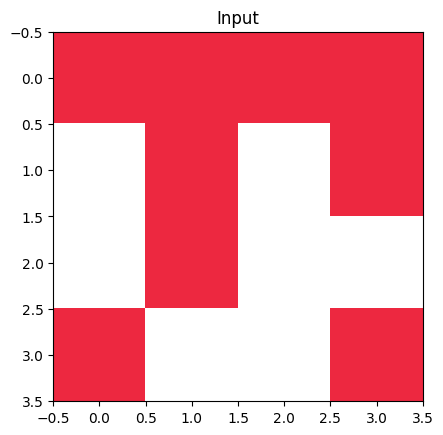

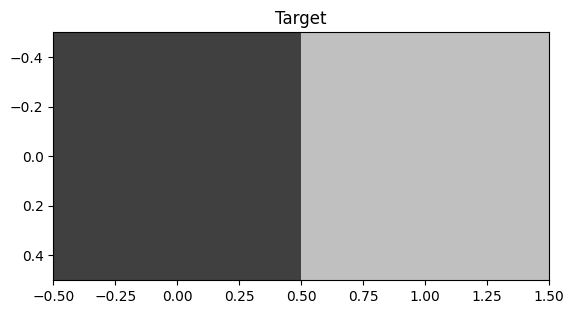

In [2]:
image = get_logo_as_rgb_image_tensor()

plot_rgb_image_tensor(image, "Input")

target = torch.tensor([0.25, 0.75], dtype=torch.float32)

plot_grayscale_image_tensor(target.unsqueeze(0), "Target")

## Exercise 1: Linear model

Build a model that maps the complete RGB image to the two target values. You will implement its linear prediction, loss, manual gradient calculation, and weight update one step at a time.

### Initialize the weights

Implement `LinearModel.init_weights`: create one small random weight for every input-output connection. Instantiate the model with a reproducible random seed and inspect the weights that connect the red input channel to each output.

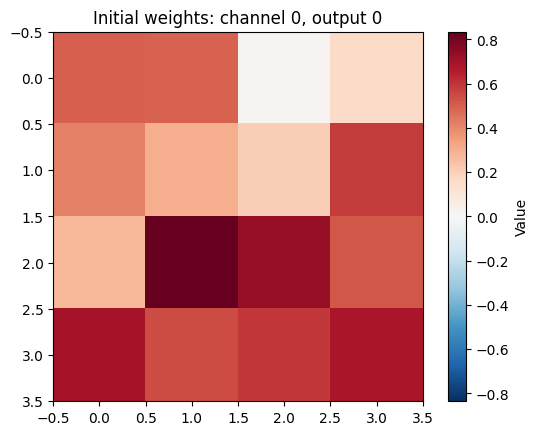

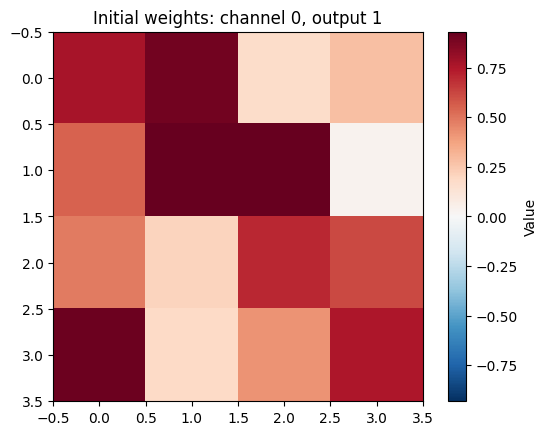

In [3]:
torch.manual_seed(0)

linear_model = LinearModel(image.shape, target.shape)

plot_scalar_image_tensor(linear_model.weights[..., RED, 0], f"Initial weights: channel {RED}, output 0")
plot_scalar_image_tensor(linear_model.weights[..., RED, 1], f"Initial weights: channel {RED}, output 1")


### Calculate the output and loss

Implement `LinearModel.calculate_output` and `LinearModel.calculate_loss`. Inspect the initial prediction and loss, verifying that the output has the same shape as the target and that the loss is a single value.

The output of each neuron on the model is a linear combination of all inputs with their corresponding weights for that neuron.

Use the mean squared error to measure the difference between output and target tensors.

Initial output: tensor([[[[0.5542, 0.8969],
          [0.5542, 0.8969],
          [0.5542, 0.8969],
          [0.5542, 0.8969]],

         [[1.2946, 1.9305],
          [0.6165, 1.0367],
          [1.2946, 1.9305],
          [0.6165, 1.0367]],

         [[1.0139, 1.4874],
          [0.2421, 0.4398],
          [1.0139, 1.4874],
          [1.0139, 1.4874]],

         [[0.3569, 0.6264],
          [1.2397, 2.0716],
          [1.2397, 2.0716],
          [0.3569, 0.6264]]],


        [[[0.5874, 0.6154],
          [0.5874, 0.6154],
          [0.5874, 0.6154],
          [0.5874, 0.6154]],

         [[0.6317, 1.2336],
          [0.3502, 0.9201],
          [0.6317, 1.2336],
          [0.3502, 0.9201]],

         [[1.4575, 1.9158],
          [0.4398, 1.0454],
          [1.4575, 1.9158],
          [1.4575, 1.9158]],

         [[0.7720, 0.2680],
          [1.5388, 1.0685],
          [1.5388, 1.0685],
          [0.7720, 0.2680]]],


        [[[0.5636, 0.7487],
          [0.5636, 0.7487],
          [0

TypeError: Invalid shape (1, 4, 4, 4, 2) for image data

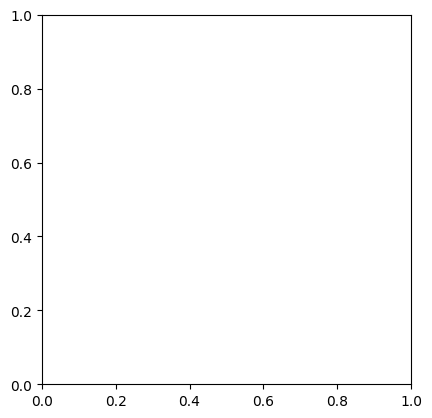

In [4]:
linear_initial_output = linear_model.calculate_output(image)
linear_initial_loss = linear_model.calculate_loss(linear_initial_output, target)

print(f"Initial output: {linear_initial_output}")
print(f"Initial loss: {linear_initial_loss.item():.6f}")

plot_grayscale_image_tensor(linear_initial_output.unsqueeze(0), "Initial linear output")

### Calculate the weight gradients

Implement `LinearModel.calculate_gradients` so that it returns the gradients of the loss with respect to the weights. Validate that the weight and gradient shapes match. Further, inspect and compare the gradients for the different input channels

Hint: Use the chain rule to decompose the calculation of the gradients $\frac{\partial L_{MSE}}{\partial weight_{ij}}$

In [ ]:
linear_gradients = linear_model.calculate_gradients(image, linear_initial_output, target)

print(f"Weight shape: {linear_model.weights.shape}")
print(f"Gradient shape: {linear_gradients.shape}")

plot_scalar_image_tensor(linear_gradients[..., RED, 0], f"Gradients: channel {RED}, output 0")
plot_scalar_image_tensor(linear_gradients[..., RED, 1], f"Gradients: channel {RED}, output 1")

### Update the weights

Implement `LinearModel.update_weights`. Perform one update and inspect the resulting weights, verifying that the method changes the model's weights and returns the updated tensor.

Note: Gradient descent moves each weight in the direction opposite its gradient. The learning rate controls the size of that step.

In [ ]:
linear_learning_rate = 0.01

linear_updated_weights = linear_model.update_weights(linear_gradients, linear_learning_rate)

plot_scalar_image_tensor(linear_updated_weights[..., RED, 0], f"Updated weights: channel {RED}, output 0")
plot_scalar_image_tensor(linear_updated_weights[..., RED, 1], f"Updated weights: channel {RED}, output 1")

### Check the weight update

Recalculate the output and loss with the updated weights. The updated loss should be lower than the initial loss; otherwise, check the update direction, gradient shape, and learning rate.

In [ ]:
linear_updated_output = linear_model.calculate_output(image)

print(f"Initial output: {linear_initial_output}")
print(f"Updated output: {linear_updated_output}")

linear_updated_loss = linear_model.calculate_loss(linear_updated_output, target)

print(f"Initial loss: {linear_initial_loss.item():.6f}")
print(f"Updated loss: {linear_updated_loss.item():.6f}")

### Train the linear model

The provided `train_step` method performs one complete learning step, while `fit` repeats it and records each loss. Train a freshly initialized model and inspect its loss curve and final prediction.

Check that:

- the loss decreases at every step
- the final output approaches the target
- the final loss is substantially smaller than the initial loss

In [ ]:
torch.manual_seed(0)

linear_model = LinearModel(image.shape, target.shape)

linear_loss_history = linear_model.fit(image, target, steps=20, learning_rate=linear_learning_rate)

plt.plot(linear_loss_history)
plt.xlabel("Training step")
plt.ylabel("MSE")
plt.title("Model training loss")
plt.show()

linear_output = linear_model.calculate_output(image)
linear_loss = linear_model.calculate_loss(linear_output, target)

print(f"Target: {target}")
print(f"Final output: {linear_output}")
print(f"Final loss: {linear_loss.item():.10f}")

plot_grayscale_image_tensor(target.unsqueeze(0), "Target")
plot_grayscale_image_tensor(linear_output.unsqueeze(0), "Final output")

## Exercise 2: Activation function

Extend the linear model with a sigmoid activation so that every output lies between 0 and 1. Implement the changed output and gradient calculations and reuse inherited behavior where appropriate.

### Initialize the linear-sigmoid model

`LinearSigmoidModel` inherits `init_weights` from `LinearModel`. Create a fresh model and inspect its initial weights. Using the same seed as before makes its initialization directly comparable with the linear model.

In [ ]:
torch.manual_seed(0)

sigmoid_model = LinearSigmoidModel(image.shape, target.shape)

plot_scalar_image_tensor(sigmoid_model.weights[..., RED, 0], f"Initial weights: channel {RED}, output 0")
plot_scalar_image_tensor(sigmoid_model.weights[..., RED, 1], f"Initial weights: channel {RED}, output 1")

### Calculate a bounded output

Implement `LinearSigmoidModel.calculate_output`: calculate the linear logits and apply the sigmoid activation. Inspect the initial output and loss, verifying that both output values lie between 0 and 1.

In [ ]:
sigmoid_initial_output = sigmoid_model.calculate_output(image)
sigmoid_initial_loss = sigmoid_model.calculate_loss(sigmoid_initial_output, target)

print(f"Initial output: {sigmoid_initial_output}")
print(f"Initial loss: {sigmoid_initial_loss.item():.6f}")

plot_grayscale_image_tensor(sigmoid_initial_output.unsqueeze(0), "Initial sigmoid output")

### Extend the manual weight gradient

Implement `LinearSigmoidModel.calculate_gradients`, adding the sigmoid derivative to the manual calculation. Inspect the resulting gradients and verify that their tensor has exactly the same shape as the weights.

Hint: The sigmoid introduces another factor in the chain rule.  Combine the MSE derivatives, the sigmoid derivatives, and the logit derivatives.

In [ ]:
sigmoid_gradients = sigmoid_model.calculate_gradients(image, sigmoid_initial_output, target)

plot_scalar_image_tensor(sigmoid_gradients[..., RED, 0], f"Gradients: channel {RED}, output 0")
plot_scalar_image_tensor(sigmoid_gradients[..., RED, 1], f"Gradients: channel {RED}, output 1")

### Update the sigmoid model's weights

The sigmoid model inherits `update_weights`, so no new implementation is needed here. Apply the gradients with the specified learning rate and inspect the updated weights. The larger learning rate compensates for the smaller gradients introduced by the sigmoid derivative.

In [ ]:
sigmoid_learning_rate = 0.2

sigmoid_updated_weights = sigmoid_model.update_weights(sigmoid_gradients, sigmoid_learning_rate)

plot_scalar_image_tensor(sigmoid_updated_weights[..., RED, 0], f"Updated weights: channel {RED}, output 0")
plot_scalar_image_tensor(sigmoid_updated_weights[..., RED, 1], f"Updated weights: channel {RED}, output 1")

### Check the weight update

Recalculate the bounded output and loss after the update. Verify that the output remains between 0 and 1 and that the updated loss is lower than the initial loss.

In [ ]:
sigmoid_updated_output = sigmoid_model.calculate_output(image)

print(f"Initial output: {sigmoid_initial_output}")
print(f"Updated output: {sigmoid_updated_output}")

sigmoid_updated_loss = sigmoid_model.calculate_loss(sigmoid_updated_output, target)

print(f"Initial loss: {sigmoid_initial_loss.item():.6f}")
print(f"Updated loss: {sigmoid_updated_loss.item():.6f}")

### Train the sigmoid model

Train a fresh `LinearSigmoidModel` and inspect the loss curve, final output, and final loss.

Part I is complete when:

- the sigmoid outputs remain between 0 and 1
- one weight update lowers the loss
- the loss decreases throughout training
- the final output approaches the target
- all gradients were calculated manually without autograd or pre-built layers

In [ ]:
torch.manual_seed(0)

sigmoid_model = LinearSigmoidModel(image.shape, target.shape)

sigmoid_loss_history = sigmoid_model.fit(image, target, steps=10, learning_rate=sigmoid_learning_rate)

plt.plot(sigmoid_loss_history)
plt.xlabel("Training step")
plt.ylabel("MSE")
plt.title("Model training loss")
plt.show()

sigmoid_output = sigmoid_model.calculate_output(image)
sigmoid_loss = sigmoid_model.calculate_loss(sigmoid_output, target)

print(f"Target: {target}")
print(f"Final output: {sigmoid_output}")
print(f"Final loss: {sigmoid_loss.item():.10f}")

plot_grayscale_image_tensor(target.unsqueeze(0), "Target")
plot_grayscale_image_tensor(sigmoid_output.unsqueeze(0), "Final output")